### 06 Final test evaluation

Fit the final random forest and the MLP (for comparison) on all 18 training participants, and evaluate them once on the 4 held-out test participants (S018, S019, S022, S025).

**Input:** `data/processed/harth_windows.csv` (from notebook 02)

**Output:** test macro F1, balanced accuracy and classification reports; confusion matrices; per-participant macro F1.

Note: The final model (random forest) and both model settings were chosen in notebook 04. The test set is only used in this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.pipeline import make_pipeline 
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score, balanced_accuracy_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

In [2]:
print(Path.cwd())
# Create data directory 
data_directory = Path("../data/processed")
print(list(data_directory.iterdir()))

C:\Users\sarab\Projects\harth_clean_test\notebooks
[WindowsPath('../data/processed/harth_windows.csv')]


In [3]:
# Read harth_windows csv file
harth_windows = pd.read_csv(data_directory/"harth_windows.csv")
harth_windows.head()

,back_x_mean,back_y_mean,back_z_mean,thigh_x_mean,thigh_y_mean,thigh_z_mean,back_mag_mean,thigh_mag_mean,back_x_sd,back_y_sd,...,back_x_range,back_y_range,back_z_range,thigh_x_range,thigh_y_range,thigh_z_range,back_mag_range,thigh_mag_range,activity,subject
0,-0.985535,0.076321,0.071897,-0.951721,0.066909,-0.300923,0.991294,1.000641,0.008179,0.015925,...,0.042021,0.106730,0.049085,0.026857,0.087156,0.065944,0.049257,0.030911,walking,S006
1,-0.990118,0.098939,0.052922,-0.970774,0.017955,-0.240916,0.996594,1.000600,0.006710,0.014250,...,0.021219,0.064559,0.039445,0.023676,0.082334,0.048104,0.021273,0.019548,standing,S006
2,-0.985489,0.114645,0.066351,-0.971958,0.013050,-0.227268,0.994405,0.998316,0.003794,0.007793,...,0.019534,0.039422,0.033895,0.007465,0.040694,0.031032,0.019653,0.008874,standing,S006
3,-0.986061,0.112886,0.061172,-0.971738,0.010761,-0.241171,0.994513,1.001399,0.004785,0.013871,...,0.021073,0.048442,0.034815,0.035844,0.036097,0.062481,0.023155,0.031511,standing,S006
4,-0.982235,0.143961,0.078188,-0.981988,0.051999,-0.167089,0.996508,1.000266,0.007308,0.028004,...,0.034060,0.127701,0.091557,0.051724,0.117495,0.212539,0.030263,0.033056,standing,S006


In [4]:
# Create a DataFrame with training data
TRAINING = ["S006", "S008", "S009", "S010", "S012", "S013", "S014", "S015", "S016", "S017", "S020", "S021", "S023", "S024", "S026", "S027", "S028", "S029"]

harth_windows_training = harth_windows[harth_windows["subject"].isin(TRAINING)]
harth_windows_training.shape
harth_windows_training.head()

,back_x_mean,back_y_mean,back_z_mean,thigh_x_mean,thigh_y_mean,thigh_z_mean,back_mag_mean,thigh_mag_mean,back_x_sd,back_y_sd,...,back_x_range,back_y_range,back_z_range,thigh_x_range,thigh_y_range,thigh_z_range,back_mag_range,thigh_mag_range,activity,subject
0,-0.985535,0.076321,0.071897,-0.951721,0.066909,-0.300923,0.991294,1.000641,0.008179,0.015925,...,0.042021,0.106730,0.049085,0.026857,0.087156,0.065944,0.049257,0.030911,walking,S006
1,-0.990118,0.098939,0.052922,-0.970774,0.017955,-0.240916,0.996594,1.000600,0.006710,0.014250,...,0.021219,0.064559,0.039445,0.023676,0.082334,0.048104,0.021273,0.019548,standing,S006
2,-0.985489,0.114645,0.066351,-0.971958,0.013050,-0.227268,0.994405,0.998316,0.003794,0.007793,...,0.019534,0.039422,0.033895,0.007465,0.040694,0.031032,0.019653,0.008874,standing,S006
3,-0.986061,0.112886,0.061172,-0.971738,0.010761,-0.241171,0.994513,1.001399,0.004785,0.013871,...,0.021073,0.048442,0.034815,0.035844,0.036097,0.062481,0.023155,0.031511,standing,S006
4,-0.982235,0.143961,0.078188,-0.981988,0.051999,-0.167089,0.996508,1.000266,0.007308,0.028004,...,0.034060,0.127701,0.091557,0.051724,0.117495,0.212539,0.030263,0.033056,standing,S006


In [5]:
# Create a DataFrame with test data
TEST = ["S018", "S019", "S022", "S025"]

harth_windows_test = harth_windows[harth_windows["subject"].isin(TEST)]
harth_windows_test.shape

(22308, 26)

In [6]:
# Seperate into inputs (24 geatures) and target (activity) for 18 training participants and 4 test participants
# Training
X_train = harth_windows_training.drop(columns=["activity", "subject"])
y_train = harth_windows_training["activity"] 
# Test
X_test = harth_windows_test.drop(columns=["activity", "subject"])
y_test = harth_windows_test["activity"]

print(X_train.shape, X_test.shape)

(96078, 24) (22308, 24)


In [7]:
# Final model chosen: Random forest with the best settings from tuning
final_forest = RandomForestClassifier(n_estimators=200, max_depth = None, min_samples_leaf = 1, n_jobs=-1, random_state=42)

# Train on all 18 participants
final_forest.fit(X_train, y_train)

# Predict the 4 test participants
pred_test_forest = final_forest.predict(X_test)

# Test-set scores
print("Macro F1: ", round(f1_score(y_test, pred_test_forest, average="macro"), 3))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, pred_test_forest), 3))
print(classification_report(y_test, pred_test_forest, digits=3))

Macro F1:  0.839
Balanced accuracy: 0.836


              precision    recall  f1-score   support

     cycling      0.971     0.856     0.910      1988
       lying      0.999     0.997     0.998      1866
     running      0.984     0.966     0.975      1078
   shuffling      0.422     0.404     0.413       565
     sitting      0.993     0.997     0.995      9652
      stairs      0.593     0.637     0.615       543
    standing      0.900     0.896     0.898      2264
     walking      0.888     0.932     0.909      4352

    accuracy                          0.936     22308
   macro avg      0.844     0.836     0.839     22308
weighted avg      0.937     0.936     0.936     22308



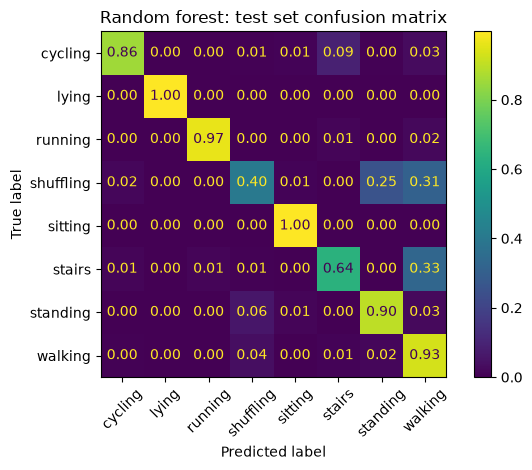

In [8]:
# Plot confusion matrix of test participants
ConfusionMatrixDisplay.from_predictions(y_test, pred_test_forest, normalize="true", values_format=".2f", xticks_rotation=45)
plt.title("Random forest: test set confusion matrix")
plt.tight_layout()
#Save
Path("../reports/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("../reports/figures/forest_test_confusionmatrix.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
# Final test using MLP
final_mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16,), alpha=0.01, activation="relu", 
                                                             solver="adam", max_iter=300, early_stopping=False, random_state=42))
# Train on all 18 participants
final_mlp.fit(X_train, y_train)

# Predict the 4 test participants
pred_test_mlp = final_mlp.predict(X_test)

# Test-set scores
print("Macro F1: ", round(f1_score(y_test, pred_test_mlp, average="macro"), 3))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, pred_test_mlp), 3))
print(classification_report(y_test, pred_test_mlp, digits=3))

Macro F1:  0.811
Balanced accuracy: 0.818
              precision    recall  f1-score   support

     cycling      0.978     0.699     0.815      1988
       lying      0.984     0.998     0.991      1866
     running      0.984     0.950     0.966      1078
   shuffling      0.406     0.421     0.414       565
     sitting      0.991     0.996     0.993      9652
      stairs      0.414     0.670     0.512       543
    standing      0.895     0.882     0.888      2264
     walking      0.888     0.930     0.909      4352

    accuracy                          0.920     22308
   macro avg      0.817     0.818     0.811     22308
weighted avg      0.930     0.920     0.922     22308



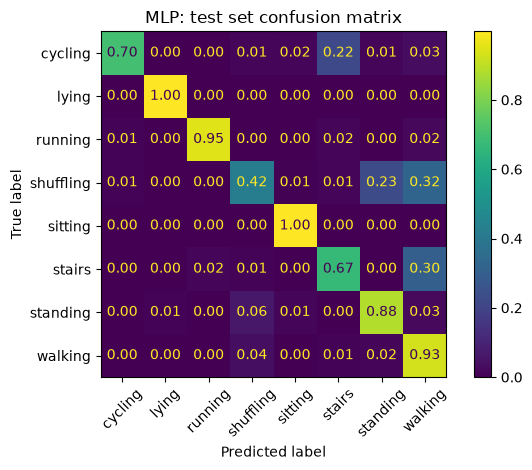

In [10]:
# Plot confusion matrix of test participants
ConfusionMatrixDisplay.from_predictions(y_test, pred_test_mlp, normalize="true", values_format=".2f", xticks_rotation=45)
plt.title("MLP: test set confusion matrix")
plt.tight_layout()
#Save
Path("../reports/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("../reports/figures/mlp_test_confusionmatrix.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
# Create results table with a row for each test subject
rows = []
subjects_test = harth_windows_test["subject"]

for subject in subjects_test.unique():
    mask = subjects_test == subject
    forest_f1 =  round(f1_score(y_test[mask], pred_test_forest[mask], average="macro"), 3)
    mlp_f1 =  round(f1_score(y_test[mask], pred_test_mlp[mask], average="macro"), 3)
    rows.append({"subject":subject, "n_windows": mask.sum(), "forest_f1": forest_f1, "mlp_f1": mlp_f1})

per_subject = pd.DataFrame(rows).round(3)
per_subject


,subject,n_windows,forest_f1,mlp_f1
0,S018,6076,0.763,0.767
1,S019,5731,0.912,0.929
2,S022,6180,0.891,0.879
3,S025,4321,0.812,0.751


In [12]:
# Check time per activity for test subjects
pd.crosstab(subjects_test, y_test)

activity,cycling,lying,running,shuffling,sitting,stairs,standing,walking
subject,,,,,,,,
S018,148,655,268,199,2851,119,677,1159
S019,274,426,88,96,3821,127,328,571
S022,261,380,43,168,2809,180,1001,1338
S025,1305,405,679,102,171,117,258,1284
